<a href="https://colab.research.google.com/github/hoyhoy1227/visionAI/blob/main/HuggingFace_OCR_GLM_Coffee_LoRA_timed.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# GLM-OCR 상품 포장 OCR — Before / FT 비교

기존 FT-B 설정(학습률 5e-5, 증강, cosine/warmup)을 단일 FT 3 epoch로 적용합니다. FT-A 선행 학습 없이 사전학습 모델에서 시작합니다.


## 1. Jupyter 커널과 작업 폴더
Python **3.11 또는 3.12** 환경을 권장합니다. Jupyter에서 이 파일을 열고 사용할 Python 커널을 선택한 뒤 위에서부터 실행하세요.
이미 Jupyter가 설치되어 있다면 별도의 새 환경을 만들 필요는 없습니다.

새 환경이 필요할 때만, Windows의 원하는 프로젝트 폴더에서 아래 명령을 실행할 수 있습니다.
```powershell
python -m venv .venv
./.venv/Scripts/python.exe -m pip install notebook ipykernel
./.venv/Scripts/python.exe -m ipykernel install --user --name glm-ocr --display-name "Python (GLM-OCR)"
./.venv/Scripts/python.exe -m notebook
```
Jupyter의 커널 메뉴에서 **Python (GLM-OCR)**을 선택하세요.
아래 셀의 `WORK_DIR`에서 결과 저장 위치를, `CACHE_DIR`에서 모델·데이터 캐시 위치를 변경할 수 있습니다.
Windows에서는 경로를 짧게 두면 긴 파일 경로 문제를 줄일 수 있습니다.

GPU 학습에는 CUDA를 지원하는 NVIDIA GPU와 GPU용 PyTorch가 필요합니다. CPU에서도 코드는 실행되지만 전체 학습은 매우 느립니다.
이 노트북은 NVIDIA CUDA 또는 CPU를 사용합니다. 장치 이름·GPU 메모리·커널 Python 경로를 다음 셀에서 확인합니다.


In [ ]:
import os, sys, shutil, subprocess, platform
from pathlib import Path

# 현재 Jupyter 작업 폴더 기준입니다. 필요하면 절대 경로로 바꾸세요.
WORK_DIR = (Path.cwd()/'glm_ocr_coffee').resolve()
CACHE_DIR = (Path.home()/'.cache'/'glm_ocr').resolve()
# 예: WORK_DIR = Path(r'C:\Projects\GLM_OCR')
# 모델/데이터를 import하기 전에 캐시 위치를 설정합니다.
os.environ['HF_HOME'] = str(CACHE_DIR)
os.environ['HF_DATASETS_CACHE'] = str(CACHE_DIR/'datasets')
os.environ['HF_HUB_DISABLE_SYMLINKS_WARNING'] = '1'
WORK_DIR.mkdir(parents=True, exist_ok=True)
CACHE_DIR.mkdir(parents=True, exist_ok=True)

print('운영체제:', platform.platform())
print('커널 Python:', sys.executable)
print('Python 버전:', sys.version.split()[0])
print('작업 폴더:', WORK_DIR)
print('캐시 폴더:', CACHE_DIR)
NVIDIA_SMI = shutil.which('nvidia-smi')
if NVIDIA_SMI is None and os.name == 'nt':
    possible_paths = [Path(os.environ.get('SystemRoot','C:/Windows'))/'System32/nvidia-smi.exe',
                      Path(os.environ.get('ProgramFiles','C:/Program Files'))/'NVIDIA Corporation/NVSMI/nvidia-smi.exe']
    NVIDIA_SMI = next((str(p) for p in possible_paths if p.is_file()), None)
if NVIDIA_SMI:
    status = subprocess.run([NVIDIA_SMI, '--query-gpu=name,memory.total,driver_version', '--format=csv'],
                            capture_output=True, text=True, errors='replace', timeout=15)
    print(status.stdout if status.returncode == 0 else status.stderr)
else:
    print('nvidia-smi 경로를 찾지 못했습니다. 다음 셀에서 PyTorch의 CUDA 사용 가능 여부를 확인합니다.')


운영체제: Linux-6.6.122+-x86_64-with-glibc2.39
커널 Python: /usr/bin/python3
Python 버전: 3.13.15
작업 폴더: /content/glm_ocr_coffee
캐시 폴더: /root/.cache/glm_ocr
name, memory.total [MiB], driver_version
Tesla T4, 15360 MiB, 580.82.07



In [ ]:
import importlib.util

# PyTorch가 없을 때만 자동 설치합니다. 이미 설치된 환경은 유지합니다.
# CPU 전용 PyTorch를 GPU용으로 바꾸려면 아래 값을 True로 바꾸고 실행한 뒤 커널을 재시작하세요.
REINSTALL_PYTORCH = False
TORCH_BACKEND = 'cu128' if NVIDIA_SMI else 'cpu'  # 필요하면 직접 'cu128' 또는 'cpu'로 지정
if TORCH_BACKEND not in {'cu128', 'cpu'}:
    raise ValueError("TORCH_BACKEND는 'cu128' 또는 'cpu'로 지정하세요.")
if importlib.util.find_spec('torch') is None or REINSTALL_PYTORCH:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '--upgrade',
                           'torch>=2.6,<3', 'torchvision', '--index-url',
                           f'https://download.pytorch.org/whl/{TORCH_BACKEND}'])
    if REINSTALL_PYTORCH:
        raise SystemExit('PyTorch 교체 완료. 커널을 재시작하고 REINSTALL_PYTORCH=False로 되돌린 뒤 다시 실행하세요.')

import torch
from packaging.version import Version
if Version(torch.__version__.split('+')[0]) < Version('2.6'):
    raise RuntimeError('PyTorch 2.6 이상이 필요합니다. REINSTALL_PYTORCH=True로 설치 후 커널을 재시작하세요.')
print('PyTorch:', torch.__version__)
print('PyTorch CUDA 빌드:', torch.version.cuda)
print('CUDA 사용 가능:', torch.cuda.is_available())
if torch.cuda.is_available():
    props = torch.cuda.get_device_properties(0)
    print('GPU:', props.name, '| GPU 메모리:', round(props.total_memory/1024**3, 1), 'GiB')
else:
    print('현재 커널은 CPU를 사용합니다. NVIDIA GPU가 있다면 드라이버와 GPU용 PyTorch 설치를 확인하세요.')


PyTorch: 2.11.0+cu130
PyTorch CUDA 빌드: 13.0
CUDA 사용 가능: True
GPU: Tesla T4 | GPU 메모리: 14.6 GiB


## 2. 현재 Jupyter 커널에 라이브러리 설치
`sys.executable -m pip`로 이 노트북 커널의 Python에 설치합니다.
전역 `PIP_CONSTRAINT`가 고정한 regex/safetensors와 새 Transformers 요구사항의 충돌을 피하도록,
이번 설치 프로세스에만 전역 constraints 환경변수를 제외합니다. 원래 환경변수나 constraints 파일은 수정하지 않습니다.
기존 torch·torchvision·torchaudio·NumPy 버전은 별도 constraints로 고정합니다.
다른 버전의 Transformers/PEFT를 이미 import한 커널이면 설치 후 **커널 재시작**을 하고 위에서부터 다시 실행하세요.
새 Python 환경에는 PyTorch 다운로드가 추가로 필요할 수 있습니다.

`GlmOcrForConditionalGeneration` ImportError가 나면 이 설치 셀을 다시 실행하고,
Jupyter 메뉴의 **Kernel → Restart Kernel**을 선택한 뒤 위에서부터 재실행하세요.
설치 후 별도의 Python 프로세스에서 GLM-OCR import까지 확인합니다.
새 Python에서 성공해도 현재 커널에는 구버전이 남아 있을 수 있으므로 반드시 커널을 재시작하세요.
`DEPRECATION` 메시지는 경고입니다. 설치 성공 여부는 마지막 import 검사 또는 실제 `ERROR`를 확인합니다.

NVIDIA 드라이버와 CUDA 설치 조합은 [PyTorch 공식 설치 안내](https://pytorch.org/get-started/locally/)를 참고하세요.
새 커널 등록 방법은 [IPython 커널 설치 안내](https://ipython.readthedocs.io/en/stable/install/kernel_install.html)를 참고하세요.


In [ ]:
import os
import sys
import subprocess
import tempfile
from pathlib import Path
from importlib.metadata import version, PackageNotFoundError

GLM_PACKAGES = [
    'transformers==5.20.1', 'peft==0.21.2', 'accelerate>=1.1,<2',
    'huggingface-hub==1.31.0', 'regex>=2025.10.22', 'safetensors>=0.8',
    'datasets==4.4.1', 'pyarrow==21.0.0', 'nltk==3.9.2', 'pandas>=2.2,<3',
    'matplotlib>=3.9,<4', 'Pillow>=10.0.1', 'tqdm>=4.66,<5', 'ipywidgets>=8.1,<9',
]

def glm_install_environment():
    install_env = os.environ.copy()
    # 현재 커널/환경의 설정은 유지하고, 이번 pip 자식 프로세스에만 적용합니다.
    for key in ('PIP_CONSTRAINT', 'PIP_BUILD_CONSTRAINT'):
        install_env.pop(key, None)
    return install_env

def glm_preserved_versions():
    # CUDA용 PyTorch와 기존 NumPy를 다른 버전으로 교체하지 않도록 보호합니다.
    pinned = []
    for name in ('torch', 'torchvision', 'torchaudio', 'numpy'):
        try:
            pinned.append(f'{name}=={version(name)}')
        except PackageNotFoundError:
            pass
    return pinned

def install_glm_dependencies():
    install_env = glm_install_environment()
    print('설치할 커널 Python:', sys.executable)
    print('이번 설치에서만 전역 PIP_CONSTRAINT/PIP_BUILD_CONSTRAINT를 제외합니다.')
    with tempfile.TemporaryDirectory(prefix='glm_ocr_install_') as temp_dir:
        preserved = Path(temp_dir)/'preserve_torch_numpy.txt'
        preserved.write_text('\n'.join(glm_preserved_versions())+'\n', encoding='utf-8')
        subprocess.check_call([
            sys.executable, '-m', 'pip', 'install', '--upgrade',
            '--upgrade-strategy', 'only-if-needed', '--constraint', str(preserved),
            *GLM_PACKAGES,
        ], env=install_env)

    # user-site 설치 및 현재 커널에 남은 구버전의 영향을 구분하기 위해 새 Python에서 검사합니다.
    verify = '''
import transformers, peft, regex, safetensors
import numpy, pyarrow, datasets
from datasets import load_dataset
assert pyarrow.__version__ == '21.0.0'
assert datasets.__version__ == '4.4.1'
from transformers import AutoProcessor, GlmOcrForConditionalGeneration
assert transformers.__version__ == '5.20.1', transformers.__version__
assert peft.__version__ == '0.21.2', peft.__version__
print('Transformers:', transformers.__version__)
print('PEFT:', peft.__version__)
print('regex:', regex.__version__)
print('safetensors:', safetensors.__version__)
print('Transformers path:', transformers.__file__)
print('GLM-OCR import 성공')
'''
    subprocess.check_call([sys.executable, '-c', verify], env=install_env)
    print('설치·import 검사 완료. Kernel → Restart Kernel 후 위에서부터 다시 실행하세요.')

install_glm_dependencies()


설치할 커널 Python: /usr/bin/python3
이번 설치에서만 전역 PIP_CONSTRAINT/PIP_BUILD_CONSTRAINT를 제외합니다.
설치·import 검사 완료. Kernel → Restart Kernel 후 위에서부터 다시 실행하세요.


## 3. Hugging Face에서 모델·데이터 확인
- [GLM-OCR 모델](https://huggingface.co/zai-org/GLM-OCR): 약 0.9B 파라미터의 멀티모달 OCR 모델.
- [Coffee-Bean-Package-Images-OCR 데이터](https://huggingface.co/datasets/Thi-Thu-Huong/Coffee-Bean-Package-Images-OCR): HRCB·LRCB 포장 이미지와 전사 JSON.
- [공식 파인튜닝 가이드](https://github.com/zai-org/GLM-OCR/blob/main/examples/finetune/README.md)

이 저장소를 `load_dataset(저장소명)`으로만 읽으면 폴더 분류 라벨이 나옵니다. **OCR 정답은 별도의 `*_actual_labels.json`**이므로 Hub에서 JSON을 받아 `load_dataset('json', ...)`으로 불러옵니다.
공식 LoRA 원리를 PEFT/PyTorch로 구현해 노트북 안에서 학습 전후를 직접 비교합니다.


## 4. 사전학습 GLM-OCR로 첫 예측
데이터로 추가 학습하기 전에 원래 모델을 불러옵니다.


In [ ]:
# 위젯이 실제로 표시되면 auto, 응답이 없거나 오류가 나면 text를 사용합니다.
import asyncio
import warnings
from IPython import get_ipython
from IPython.display import display, HTML
from tqdm.std import tqdm as text_tqdm

async def select_progress(timeout=6.0):
    shell = get_ipython()
    if shell is None or not hasattr(shell, 'kernel'):
        return 'text'
    probe = handle = None
    try:
        import ipywidgets as widgets
        # view_count는 Python import 성공 여부가 아닌 브라우저 표시 응답을 확인합니다.
        probe = widgets.HBox([
            widgets.HTML('진행률 표시 확인 중…'),
            widgets.IntProgress(value=1, min=0, max=1),
        ], _view_count=0)
        handle = display(probe, display_id=True)
        deadline = asyncio.get_running_loop().time() + timeout
        while asyncio.get_running_loop().time() < deadline:
            if (probe._view_count or 0) > 0:
                return 'auto'
            await asyncio.sleep(0.1)
    except Exception:
        pass
    finally:
        if handle is not None:
            handle.update(HTML(''))
        if probe is not None:
            for child in probe.children:
                child.close()
            probe.close()
    return 'text'

PROGRESS_MODE = await select_progress()
import tqdm.auto as tqdm_auto_module
if PROGRESS_MODE == 'auto':
    try:
        from tqdm.auto import tqdm
        # 이전 실행에서 text로 전환했을 수 있으므로 정상 위젯 모드를 복구합니다.
        from tqdm.notebook import tqdm as notebook_tqdm
        tqdm_auto_module.tqdm = notebook_tqdm
        tqdm = notebook_tqdm
    except Exception:
        PROGRESS_MODE = 'text'
if PROGRESS_MODE == 'text':
    from tqdm import tqdm
    # 이후 import되는 HF Hub/datasets의 다운로드 진행률에도 동일하게 적용합니다.
    tqdm_auto_module.tqdm = text_tqdm
    tqdm_auto_module.trange = lambda *args, **kwargs: text_tqdm(range(*args), **kwargs)
print('진행률 표시:', PROGRESS_MODE)

import os, io, json, math, random, re, hashlib, unicodedata, gc
from pathlib import Path
from functools import lru_cache
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from torchvision import transforms as T
from IPython.display import display
import sys
from importlib.metadata import version as distribution_version
import transformers

print('커널 Python:', sys.executable)
print('Transformers 설치 버전:', distribution_version('transformers'))
print('Transformers 로드 버전:', transformers.__version__)
print('Transformers 경로:', transformers.__file__)
if transformers.__version__ != distribution_version('transformers'):
    raise RuntimeError('설치된 Transformers와 커널에 남은 버전이 다릅니다. '
                       'Kernel → Restart Kernel 후 위에서부터 재실행하세요.')
try:
    from transformers import AutoProcessor, GlmOcrForConditionalGeneration
except Exception as error:
    raise RuntimeError(
        '현재 커널에서 GLM-OCR 클래스를 불러오지 못했습니다. '
        '설치 셀에서 transformers==5.20.1, peft==0.21.2를 설치한 뒤 '
        'Kernel → Restart Kernel 후 다시 실행하세요. '
        f'설치 버전={distribution_version("transformers")}, 원본 오류={type(error).__name__}: {error}'
    ) from error
import peft
from huggingface_hub import hf_hub_download, HfApi

SEED = 42
MODEL_ID = 'zai-org/GLM-OCR'
MODEL_REVISION = '2e85a62840ccac27daa451df36c736c4636b8628'
DATASET_ID = 'Thi-Thu-Huong/Coffee-Bean-Package-Images-OCR'
DATASET_REVISION = '24ceed23dabb11265fba54ed75e7538925898f7d'
BASE = WORK_DIR
OUT = BASE/'results_ft_timed'; OUT.mkdir(parents=True, exist_ok=True)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
DTYPE = torch.bfloat16 if DEVICE.type == 'cuda' and torch.cuda.is_bf16_supported() else torch.float32
MIN_PIXELS, MAX_PIXELS = 112*112, 2*448*448
MAX_TARGET_TOKENS = 256  # EOS 포함. 이보다 긴 정답은 통째로 제외하고 개수를 출력
MAX_NEW_TOKENS = 256    # 모든 모델에서 동일, 정답 길이와 무관
def seed_all(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
seed_all(SEED)

processor = AutoProcessor.from_pretrained(MODEL_ID, revision=MODEL_REVISION)
processor.image_processor.size = {'shortest_edge': MIN_PIXELS, 'longest_edge': MAX_PIXELS}
processor.tokenizer.padding_side = 'left'
if processor.tokenizer.pad_token_id is None:
    processor.tokenizer.pad_token = processor.tokenizer.eos_token
EOS_ID = processor.tokenizer.eos_token_id
PAD_ID = processor.tokenizer.pad_token_id
messages = [{'role': 'user', 'content': [
    {'type': 'image'}, {'type': 'text', 'text': 'Text Recognition:'}]}]
PROMPT = processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True,
                                       enable_thinking=False)
model = GlmOcrForConditionalGeneration.from_pretrained(
    MODEL_ID, revision=MODEL_REVISION, dtype=DTYPE, attn_implementation='sdpa').to(device=DEVICE, dtype=DTYPE).eval()
model.config.use_cache = False
model.config.text_config.use_cache = False

def normalize_text(text):
    # 대소문자와 줄/구분자 차이를 줄이되, 숫자·소수점·단위·악센트는 보존합니다.
    text = unicodedata.normalize('NFKC', str(text)).casefold()
    return re.sub(r'\s+', ' ', re.sub(r'[;\r\n]+', ' ', text)).strip()

def to_device(batch):
    return {k: v.to(device=DEVICE, dtype=DTYPE) if torch.is_floating_point(v) else v.to(DEVICE)
            for k, v in batch.items()}

@torch.inference_mode()
def predict_images(images, return_raw=False):
    model.eval()
    batch = processor(text=[PROMPT]*len(images), images=images, padding=True, return_tensors='pt')
    batch = to_device(batch)
    output = model.generate(**batch, max_new_tokens=MAX_NEW_TOKENS, do_sample=False,
                            num_beams=1, use_cache=True, pad_token_id=PAD_ID)
    # 입력 프롬프트를 제외하고 새로 생성한 token만 평가합니다.
    generated = output[:, batch['input_ids'].shape[1]:]
    raw = processor.tokenizer.batch_decode(generated, skip_special_tokens=True,
                                           clean_up_tokenization_spaces=False)
    return raw if return_raw else [normalize_text(t) for t in raw]

print('device:', DEVICE, '| dtype:', DTYPE)
print('Transformers:', transformers.__version__, '| PEFT:', peft.__version__)
print('전처리 한도:', processor.image_processor.size)
print('결과 저장 위치:', OUT.resolve())


진행률 표시: text
커널 Python: /usr/bin/python3
Transformers 설치 버전: 5.20.1
Transformers 로드 버전: 5.20.1
Transformers 경로: /usr/local/lib/python3.13/dist-packages/transformers/__init__.py


Loading weights: 100%|██████████| 510/510 [00:00<00:00, 1796.39it/s]


device: cuda | dtype: torch.bfloat16
Transformers: 5.20.1 | PEFT: 0.21.2
전처리 한도: {'shortest_edge': 12544, 'longest_edge': 401408}
결과 저장 위치: /content/glm_ocr_coffee/results_ft_timed


In [ ]:
from datasets import load_dataset

repo_files = set(HfApi().list_repo_files(DATASET_ID, repo_type='dataset', revision=DATASET_REVISION))
records, exclusions = [], {'missing_image': 0, 'empty': 0, 'too_long': 0}
for subset in ['HRCB', 'LRCB']:
    json_path = hf_hub_download(DATASET_ID, f'{subset}_actual_labels.json',
                                repo_type='dataset', revision=DATASET_REVISION)
    table = load_dataset('json', data_files=json_path, split='train')
    for i, row in enumerate(table):
        filename = row['image_file']
        member = f'{subset}/{filename}'
        if member not in repo_files:
            exclusions['missing_image'] += 1; continue
        text = str(row['label']).strip()
        if not normalize_text(text): exclusions['empty'] += 1; continue
        n_tokens = len(processor.tokenizer.encode(text, add_special_tokens=False)) + 1
        if n_tokens > MAX_TARGET_TOKENS:
            exclusions['too_long'] += 1; continue
        # 바코드/상품 ID가 같은 front·ingredients·고저해상도 사진을 같은 그룹으로 묶습니다.
        product_id = Path(filename).stem.split('_')[0]
        records.append({'sample_id': f'{subset}:{i}:{filename}', 'member': member,
                        'subset': subset, 'product_id': product_id, 'text': text,
                        'target_tokens': n_tokens})
print('정답과 이미지가 짝을 이루고 길이 제한을 통과한 이미지:', len(records))
print('제외:', exclusions)
assert records, '사용 가능한 데이터가 없습니다.'

@lru_cache(maxsize=None)
def local_image_path(member):
    return hf_hub_download(DATASET_ID, member, repo_type='dataset', revision=DATASET_REVISION)

def open_record(record):
    path = local_image_path(record['member'])
    with Image.open(path) as im:
        return ImageOps.exif_transpose(im).convert('RGB')

preview = records[0]
preview_image = open_record(preview)


정답과 이미지가 짝을 이루고 길이 제한을 통과한 이미지: 1144
제외: {'missing_image': 2, 'empty': 0, 'too_long': 14}


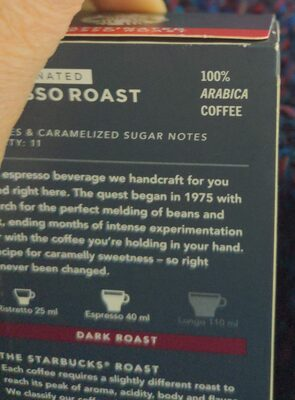

정답: ESPRESSO ROAST; 100% ARABICA COFFEE; TASTE: 11; An espresso beverage we handcraft for you right here. The quest began in 1975 with research for the perfect melding of beans and the endless months of intense experimentation with the coffee you’re holding in your hand. Recipe for caramelly sweetness – so right never been changed.; Espresso 25 ml; Espresso 40 ml; Lungo 110 ml; DARK ROAST; THE STARBUCKS® ROAST; The Starbucks® roast experience is slightly different from the rest. We classify our coffee by cup aroma, acidity, body and taste.
Before: NATED
100%
ARABICA
COFFEE
PISO ROAST
TES & CARAMELIZED SUGAR NOTES
TITY: 11
espresso beverage we handcraft for you
and right here. The quest began in 1975 with
arch for the perfect melding of beans and
ending months of intense experimentation
with the coffee you're holding in your hand.
recipe for caramelly sweetness - so right
never been changed.
Espresso 25 ml
Espresso 40 ml
Large 150 ml
DARK ROAST
THE STARBUCKS* ROAST
Each coffee requires 

In [ ]:
first_prediction = predict_images([preview_image], return_raw=True)[0]
display(preview_image.resize((max(1, round(preview_image.width*min(1, 600/preview_image.height))),
                              max(1, round(preview_image.height*min(1, 600/preview_image.height))))))
print('정답:', preview['text'])
print('Before:', first_prediction)


포장 이미지 전체의 글자를 읽습니다. 글자 크기·배경·촬영 품질뿐 아니라 여러 줄을 읽는 순서도 오차에 영향을 줍니다.
이 실습의 정답은 데이터셋이 제공한 전사입니다. 글자 위치 검출 mAP는 평가하지 않습니다.


## 5. 내 상품 포장 이미지로 예측하기 (선택)
업로드 창 대신 PC의 이미지 파일 경로를 사용합니다. 아래 `MY_IMAGE_PATH`를 지정하세요.
건너뛰려면 `None`을 유지합니다. 상대 경로는 위에서 출력한 Jupyter 작업 위치(`Path.cwd()`)를 기준으로 합니다.
Windows 경로 예: `Path(r'C:\Users\your_name\Pictures\coffee.jpg')`


In [ ]:
MY_IMAGE_PATH = None  # 예: Path(r'C:\Users\your_name\Pictures\coffee.jpg')
if MY_IMAGE_PATH is not None:
    MY_IMAGE_PATH = Path(MY_IMAGE_PATH).expanduser().resolve()
    if not MY_IMAGE_PATH.is_file():
        raise FileNotFoundError(f'이미지 파일을 찾지 못했습니다: {MY_IMAGE_PATH}')


In [ ]:
if MY_IMAGE_PATH is not None:
    with Image.open(MY_IMAGE_PATH) as im:
        own_image = ImageOps.exif_transpose(im).convert('RGB')
    print(MY_IMAGE_PATH.name, '→', predict_images([own_image], return_raw=True)[0])
    preview_own = own_image.copy(); preview_own.thumbnail((600,600)); display(preview_own)
else:
    print('내 이미지 예측을 건너뜁니다.')


내 이미지 예측을 건너뜁니다.


## 6. 데이터 탐색
HRCB와 LRCB를 함께 사용하며, POIE 폴더의 이미지는 이번 실습에 포함하지 않습니다.
공식 train/validation/test 분할이 없으므로 상품 ID 기준으로 새로 나눕니다.
빈 전사, 이미지가 없는 주석, 256 token을 넘는 긴 전사는 제외합니다. 정답을 중간에서 잘라 학습하지 않습니다.


,images,products,mean_target_tokens
subset,,,
HRCB,497,396,59.935614
LRCB,647,490,61.539413


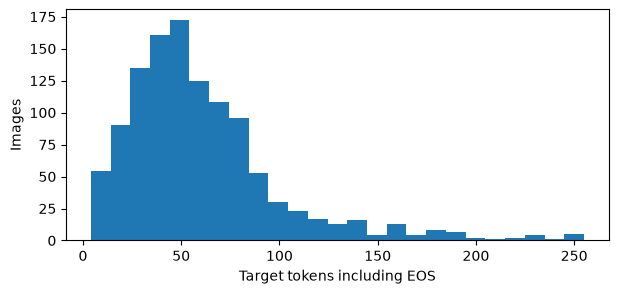

In [ ]:
display(pd.DataFrame(records).groupby('subset').agg(images=('sample_id', 'size'),
    products=('product_id', 'nunique'), mean_target_tokens=('target_tokens', 'mean')))
plt.figure(figsize=(7, 3))
plt.hist([r['target_tokens'] for r in records], bins=25)
plt.xlabel('Target tokens including EOS'); plt.ylabel('Images'); plt.show()


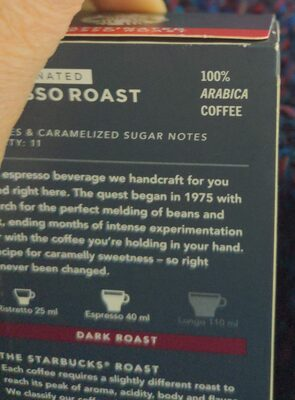

ID: HRCB:0:7613038176062_front.jpg
GT: ESPRESSO ROAST; 100% ARABICA COFFEE; TASTE: 11; An espresso beverage we handcraft for you right here. The quest began in 1975 with research for the perfect melding of beans and the endless months of intense experimentation with the coffee you’re holding in your hand. Recipe for caramelly sweetness – so right never been changed.; Espresso 25 ml; Espresso 40 ml; Lungo 110 ml; DARK ROAST; THE STARBUCKS® ROAST; The Starbucks® roast experience is slightly different from the rest. We classify our coffee by cup aroma, acidity, body and taste.


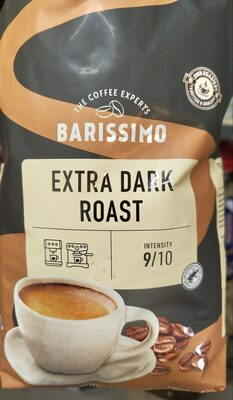

ID: HRCB:1:4047247981170_front.jpg
GT: THE COFFEE EXPERTS; BARISSIMO; EXTRA DARK; ROAST; INTENSITY; 9/10


In [ ]:
def show_samples(selected, predictions=None):
    for i, record in enumerate(selected):
        im = open_record(record); im.thumbnail((500, 500)); display(im)
        print('ID:', record['sample_id'])
        print('GT:', record['text'])
        if predictions is not None: print('Prediction:', predictions[i])
show_samples(records[:2])


### 연습: 서로 다른 포장 이미지 3개 예측
상품명·원재료·용량과 같은 글자를 얼마나 읽었는지 확인하세요.


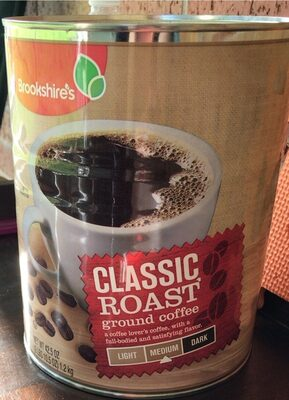

ID: HRCB:231:0092825921479_front.jpg
GT: Brookshire's; CLASSIC ROAST; ground coffee; & coffee lover's coffee, with a bold-bodied and satisfying flavor; LIGHT; MEDIUM; DARK; 12 oz (340 g) 2.12 kg
Prediction: brookshire's
CLASSIC ROAST
ground coffee
a coffee lover's coffee with a
high boiling and heating power
LIGHT MEDIUM DARK
NET WT 12.49


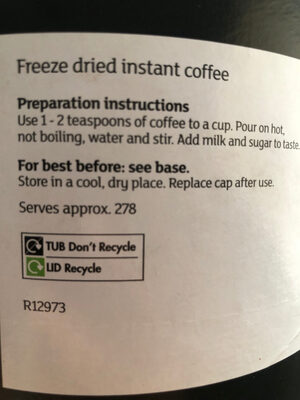

ID: HRCB:52:01398458_ingredients.jpg
GT: Freeze dried instant coffee; Preparation instructions Use 1 - 2 teaspoons of coffee to a cup. Pour on hot, not boiling, water and stir. Add milk and sugar to taste.; For best before: see base. Store in a cool, dry place. Replace cap after use.; Serves approx. 278; R12973
Prediction: Freeze dried instant coffee
Preparation instructions
Use 1 - 2 teaspoons of coffee to a cup. Pour on hot,
not boiling, water and stir. Add milk and sugar to taste.
For best before: see base.
Store in a cool, dry place. Replace cap after use.
Serves approx. 278
TUB Don't Recycle
UD Recycle
R12973


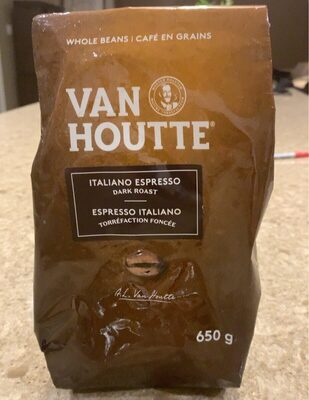

ID: LRCB:71:0062151301122_front.jpg
GT: WHOLE BEANS | CAFÉ EN GRAINS; VAN HOUTTE; ITALIANO ESPRESSO; DARK ROAST; ESPRESSO ITALIANO; TORRÉFACTION FONCÉE; 650 g
Prediction: WHOLE BEANS | CAFÉ EN GRAINS
VAN
HOUTTE
ITALIANO ESPRESSO
DARK ROAST
ESPRESSO ITALIANO
TORREFACTION FONCÉE
650 g


In [ ]:
examples = random.Random(SEED).sample(records, 3)
# 메모리를 아끼기 위해 한 장씩 생성합니다.
example_predictions = [predict_images([open_record(r)], return_raw=True)[0] for r in examples]
show_samples(examples, example_predictions)


## 7. 전이학습: 문자 디코더의 LoRA
GLM-OCR은 이미지 특징을 받아 문자열을 생성합니다. 이번에는 기존 시각 인코더와 언어 모델 가중치를 고정하고,
**문자 디코더의 attention·MLP에 추가한 LoRA 가중치**를 역전파로 학습합니다.
출력층이나 라벨 이름만 바꾸는 작업이 아닙니다. 전체 모델의 모든 기존 가중치를 업데이트하는 방식과는 구분합니다.


In [ ]:
from torch import nn
TARGET_SUFFIXES = ('q_proj', 'k_proj', 'v_proj', 'o_proj', 'gate_up_proj', 'down_proj')
target_modules = [name for name, module in model.named_modules()
                  if name.startswith('model.language_model.layers.')
                  and name.endswith(TARGET_SUFFIXES) and isinstance(module, nn.Linear)]
assert target_modules, 'LoRA 적용 대상을 찾지 못했습니다. 설치 버전을 확인하세요.'
print('전체 파라미터:', f'{sum(p.numel() for p in model.parameters()):,}')
print('LoRA 적용 Linear 수:', len(target_modules))
print(*target_modules[:6], sep='\n')


전체 파라미터: 1,107,405,824
LoRA 적용 Linear 수: 96
model.language_model.layers.0.self_attn.q_proj
model.language_model.layers.0.self_attn.k_proj
model.language_model.layers.0.self_attn.v_proj
model.language_model.layers.0.self_attn.o_proj
model.language_model.layers.0.mlp.gate_up_proj
model.language_model.layers.0.mlp.down_proj


## 비교 조건
Before는 adapter를 끈 사전학습 모델이며 FT는 단일 LoRA 학습 결과입니다. 동일한 test 이미지와 생성 조건으로 비교합니다.


## 8. 파인튜닝 준비
데이터 분할, 정답 마스킹, 평가 함수와 학습 설정을 정의합니다.


In [ ]:
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence
from nltk import edit_distance
from peft import LoraConfig, get_peft_model, get_peft_model_state_dict, set_peft_model_state_dict

N_TRAIN, N_VAL, N_TEST = 128, 32, 32  # 전체 상품 포장 이미지 수
BATCH_SIZE = 1
GRAD_ACCUM = 8
EVAL_BATCH_SIZE = 2  # GPU 메모리가 부족하면 1로 변경
N_VAL_METRICS = 8   # 검증 CER/WER 계산용 고정 부분집합; loss는 검증 전체 사용
EPOCHS = 3
STAGES = {
    'FT': dict(epochs=EPOCHS, lr=5e-5, augment=True, cosine=True),
}
print('이미지 수:', N_TRAIN, N_VAL, N_TEST, '| effective batch:', BATCH_SIZE*GRAD_ACCUM)
print('검증 loss:', N_VAL, '장 | 검증 CER/WER:', min(N_VAL_METRICS,N_VAL), '장')
display(pd.DataFrame(STAGES).T)


이미지 수: 128 32 32 | effective batch: 8
검증 loss: 32 장 | 검증 CER/WER: 8 장


,epochs,lr,augment,cosine
FT,3,0.00005,True,True


### 8-1. 상품 ID 기준 분할과 중복 검사
고해상도/저해상도 사진, front/ingredients 사진의 상품 ID가 같으면 반드시 같은 split에 배정합니다.
작은 실습에서 상품 다양성을 확보하기 위해 상품 ID당 최대 한 장을 무작위로 선택합니다.
원본 RGB 픽셀이 완전히 같은 이미지도 split 사이에서 중복 사용하지 않습니다. 유사 이미지 전체를 판별하는 검사는 아닙니다.
검증·평가에는 증강을 하지 않습니다. FT에서만 약한 색상 변화와 흐림을 적용합니다.


In [ ]:
# 상품 ID당 한 장만 사용합니다. 같은 상품의 다른 해상도·다른 면은 다른 split에 넣지 않습니다.
rng = random.Random(SEED)
groups = {}
for r in records: groups.setdefault(r['product_id'], []).append(r)
group_ids = sorted(groups); rng.shuffle(group_ids)
candidates = [rng.choice(groups[product_id]) for product_id in group_ids]
print('사용 가능한 상품 그룹:', len(candidates))

# 필요한 이미지와 소량의 중복 대체 후보만 미리 받아 다운로드 시간을 줄입니다.
from concurrent.futures import ThreadPoolExecutor
prefetch_count = min(len(candidates), N_TRAIN+N_VAL+N_TEST+32)
with ThreadPoolExecutor(max_workers=4) as pool:
    list(tqdm(pool.map(local_image_path, [r['member'] for r in candidates[:prefetch_count]]),
              total=prefetch_count, desc='Hugging Face 이미지 다운로드'))

cursor = 0
used_hashes = set()
def take_unique(count, split):
    global cursor
    selected = []
    while cursor < len(candidates):
        r = candidates[cursor]; cursor += 1
        im = open_record(r)
        digest = hashlib.sha256(str(im.size).encode()+im.tobytes()).hexdigest()
        if digest in used_hashes: continue
        used_hashes.add(digest)
        selected.append(dict(r, split=split, pixel_sha256=digest))
        if len(selected) == count: return selected
    raise ValueError(f'{split}: {count}장 필요, {len(selected)}장 확보. 이미지 수를 256/64/64로 줄여 재실행하세요.')

# 앞쪽 split을 우선 보존하고, 후속 split에서는 중복 이미지를 제외합니다.
val_records = take_unique(N_VAL, 'validation')
test_records = take_unique(N_TEST, 'test')
train_records = take_unique(N_TRAIN, 'train')
split_records = {'train': train_records, 'validation': val_records, 'test': test_records}
for a, b in [('train', 'validation'), ('train', 'test'), ('validation', 'test')]:
    assert not ({r['product_id'] for r in split_records[a]} & {r['product_id'] for r in split_records[b]})
all_records = train_records+val_records+test_records
assert len({r['pixel_sha256'] for r in all_records}) == len(all_records)
pd.DataFrame(all_records).to_json(OUT/'split_manifest.json', orient='records', indent=2, force_ascii=False)

aug = T.Compose([T.ColorJitter(brightness=.10, contrast=.10, saturation=.05),
                 T.RandomApply([T.GaussianBlur(3, sigma=(.1, .5))], p=.1)])
class PackageDataset(Dataset):
    def __init__(self, rows, augment=False): self.rows, self.augment = rows, augment
    def __len__(self): return len(self.rows)
    def __getitem__(self, index):
        row = self.rows[index]; image = open_record(row)
        if self.augment: image = aug(image)
        return {'image': image, 'text': row['text'], 'sample_id': row['sample_id']}

def make_loader(rows, train=False, augment=False, seed=SEED):
    return DataLoader(PackageDataset(rows, augment), batch_size=BATCH_SIZE if train else EVAL_BATCH_SIZE, shuffle=train,
                      num_workers=0, drop_last=False, collate_fn=lambda batch: batch,
                      generator=torch.Generator().manual_seed(seed))
val_loader, test_loader = make_loader(val_records), make_loader(test_records)
assert N_VAL_METRICS > 0
val_metric_records = random.Random(SEED+997).sample(val_records, min(N_VAL_METRICS,len(val_records)))
val_metric_ids = {r['sample_id'] for r in val_metric_records}
(OUT/'validation_metric_sample_ids.json').write_text(
    json.dumps(sorted(val_metric_ids),ensure_ascii=False,indent=2),encoding='utf-8')
print('매 epoch 고정 검증 CER/WER 이미지 수:',len(val_metric_ids))
display(pd.DataFrame([{'split': s, 'images': len(rs), 'products': len({r['product_id'] for r in rs})}
                      for s, rs in split_records.items()]))


사용 가능한 상품 그룹: 843


Hugging Face 이미지 다운로드: 100%|██████████| 224/224 [00:00<00:00, 2463.63it/s]


매 epoch 고정 검증 CER/WER 이미지 수: 8


,split,images,products
0,train,128,128
1,validation,32,32
2,test,32,32


### 8-2. 정답을 학습하는 위치와 평가 지표
학습 라벨은 **정답 문자열 + EOS**에만 둡니다. 프롬프트·이미지 token·padding은 `-100`으로 마스킹합니다.
pad와 EOS가 같은 token ID여도 실제 정답 EOS는 학습합니다.

- **CER ↓**: 전체 문자 편집거리 합 / 전체 정답 문자 수.
- **WER ↓**: 전체 단어 편집거리 합 / 전체 정답 단어 수.
- **Text exact match ↑**: 정규화 후 전체 전사 문자열이 완전히 같은 이미지 비율.

학습 중 검증 지표는 고정 32장, 최종 평가 지표는 전체 평가 128장으로 계산합니다.
여러 줄 전사이므로 exact match는 엄격합니다. 단어 순서가 다르면 CER·WER도 달라집니다.
숫자·소수점·단위를 보존하고 대소문자·공백·세미콜론 구분 차이만 정규화합니다.


In [ ]:
def supervised_batch(examples):
    prepared = []
    for example in examples:
        prefix = processor(text=[PROMPT], images=[example['image']], return_tensors='pt')
        answer = processor.tokenizer.encode(example['text'], add_special_tokens=False)+[EOS_ID]
        if len(answer) > MAX_TARGET_TOKENS:
            raise ValueError('긴 정답은 데이터 준비에서 제외해야 합니다. 정답을 잘라내지 않습니다.')
        ids = prefix['input_ids'][0]
        target = torch.tensor(answer, dtype=ids.dtype)
        prepared.append({
            'input_ids': torch.cat([ids, target]),
            'attention_mask': torch.ones(len(ids)+len(target), dtype=torch.long),
            'mm_token_type_ids': torch.cat([prefix['mm_token_type_ids'][0], torch.zeros_like(target)]),
            'labels': torch.cat([torch.full_like(ids, -100), target]),
            'pixel_values': prefix['pixel_values'], 'image_grid_thw': prefix['image_grid_thw'],
        })
    batch = {key: pad_sequence([r[key] for r in prepared], batch_first=True, padding_value=pad)
             for key, pad in [('input_ids', PAD_ID), ('attention_mask', 0),
                              ('mm_token_type_ids', 0), ('labels', -100)]}
    batch['pixel_values'] = torch.cat([r['pixel_values'] for r in prepared], dim=0)
    batch['image_grid_thw'] = torch.cat([r['image_grid_thw'] for r in prepared], dim=0)
    assert (batch['labels'] != -100).any(dim=1).all()
    return to_device(batch)

def metrics_from_rows(rows):
    return {'cer': sum(r['char_edits'] for r in rows)/sum(len(r['truth']) for r in rows),
            'wer': sum(r['word_edits'] for r in rows)/sum(len(r['truth'].split()) for r in rows),
            'text_exact_match': float(np.mean([r['correct'] for r in rows]))}

@torch.inference_mode()
def evaluate(loader, compute_predictions=True, prediction_ids=None):
    model.eval(); loss_sum = 0.; token_count = 0; rows = []
    for examples in tqdm(loader, desc='평가', leave=False):
        batch = supervised_batch(examples)
        n_tokens = int((batch['labels'][:, 1:] != -100).sum())
        outputs = model(**batch, use_cache=False)
        loss = outputs.loss
        if not torch.isfinite(loss): raise FloatingPointError('유한하지 않은 평가 loss')
        loss_sum += float(loss)*n_tokens; token_count += n_tokens
        del outputs, batch
        if compute_predictions:
            prediction_examples = (examples if prediction_ids is None else
                                   [x for x in examples if x['sample_id'] in prediction_ids])
            if not prediction_examples: continue
            # 정답 문자열·길이를 전달하지 않습니다. 지정한 이미지에서만 생성합니다.
            raw_predictions = predict_images([x['image'] for x in prediction_examples], return_raw=True)
            for example, raw in zip(prediction_examples, raw_predictions):
                truth, prediction = normalize_text(example['text']), normalize_text(raw)
                rows.append({'sample_id': example['sample_id'], 'truth': truth, 'prediction': prediction,
                             'raw_prediction': raw, 'char_edits': edit_distance(truth, prediction),
                             'word_edits': edit_distance(truth.split(), prediction.split()),
                             'correct': truth == prediction})
    result = {'loss': loss_sum/max(1, token_count)}
    if compute_predictions:
        if prediction_ids is not None:
            assert {r['sample_id'] for r in rows} == set(prediction_ids), '고정 검증 표본 누락'
        result.update(metrics_from_rows(rows))
    return result, pd.DataFrame(rows)


### 8-3. 실제 학습할 LoRA 연결
rank 8의 adapter를 문자 디코더의 attention·MLP에 연결합니다. 시각 인코더·연결기·기존 출력층은 고정합니다.
처음 연결한 LoRA는 출력에 영향을 주지 않도록 초기화되며, 학습 후 adapter 가중치가 변합니다.


In [ ]:
# torchao 라이브러리를 peft 호환 버전(0.16.0 이상)으로 업데이트합니다.
!pip install --upgrade "torchao>=0.16.0"

In [ ]:
if hasattr(model, 'peft_config'):
    raise RuntimeError('이미 LoRA가 연결되었습니다. 이 셀을 중복 실행했다면 모델 로딩 셀부터 다시 실행하세요.')
model = get_peft_model(model, LoraConfig(
    r=8, lora_alpha=16, lora_dropout=.05, target_modules=target_modules,
    bias='none', task_type='CAUSAL_LM', revision=MODEL_REVISION))
model.gradient_checkpointing_enable(gradient_checkpointing_kwargs={'use_reentrant': False})
model.print_trainable_parameters()
trainable_names = [n for n, p in model.named_parameters() if p.requires_grad]
assert trainable_names and all('lora_' in n for n in trainable_names)
assert all('language_model.layers.' in n for n in trainable_names)

def adapter_state():
    return {k: v.detach().cpu().clone() for k, v in get_peft_model_state_dict(model).items()}
def load_adapter_state(state):
    result = set_peft_model_state_dict(model, state, adapter_name='default')
    assert not result.unexpected_keys, result.unexpected_keys
INITIAL_ADAPTER = adapter_state()


trainable params: 3,735,552 || all params: 1,111,141,376 || trainable%: 0.3362


## FT 학습 및 시간 기록
에폭별 순수 학습 시간, 검증 시간, 체크포인트 저장을 포함한 에폭 합계와 누적 시간을 출력합니다. CUDA 작업 완료를 기다려 측정합니다.
전체 시간은 초기 Before 검증·최종 test·마지막 adapter 내보내기를 제외한 FT 루프 기준입니다. 기존 완료된 학습의 시간을 복원하지는 않습니다.


In [ ]:
import time

def sync_device():
    if DEVICE.type == "cuda": torch.cuda.synchronize(DEVICE)

def duration(seconds):
    hours, rest = divmod(int(round(seconds)), 3600)
    minutes, seconds = divmod(rest, 60)
    return f"{hours:02d}:{minutes:02d}:{seconds:02d}"

history, checkpoint_info = [], {}
def score_key(metrics): return (metrics['loss'], metrics['cer'])
def cosine_factor(step, total):
    warmup = max(1, round(total*.1))
    if step < warmup: return (step+1)/warmup
    progress = min(1., (step-warmup)/max(1, total-warmup))
    return .1+.9*.5*(1+math.cos(math.pi*progress))

def fit_stage(stage, config, initial_val):
    seed = SEED+1; seed_all(seed)
    loader = make_loader(train_records, train=True, augment=config['augment'], seed=seed)
    optimizer = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad],
                                  lr=config['lr'], weight_decay=.01)
    total_updates = math.ceil(len(loader)/GRAD_ACCUM)*config['epochs']
    scheduler = (torch.optim.lr_scheduler.LambdaLR(optimizer, lambda s: cosine_factor(s, total_updates))
                 if config['cosine'] else None)
    path = OUT/f'{stage}_best_adapter.pt'
    torch.save(adapter_state(), path)
    best_val, best_epoch = dict(initial_val), 0
    sync_device(); stage_started = time.perf_counter()
    for epoch in range(1, config['epochs']+1):
        sync_device(); epoch_started = time.perf_counter()
        model.train(); optimizer.zero_grad(set_to_none=True)
        total_loss = 0.; total_tokens = 0; updates = 0
        lr_start = optimizer.param_groups[0]['lr']
        for index, examples in enumerate(tqdm(loader, desc=f'{stage} epoch {epoch}')):
            batch = supervised_batch(examples)
            n_tokens = int((batch['labels'][:, 1:] != -100).sum())
            outputs = model(**batch, use_cache=False)
            loss = outputs.loss
            if not torch.isfinite(loss): raise FloatingPointError('유한하지 않은 학습 loss')
            group_start = (index//GRAD_ACCUM)*GRAD_ACCUM
            group_size = min(GRAD_ACCUM, len(loader)-group_start)
            (loss/group_size).backward()
            total_loss += float(loss.detach())*n_tokens; total_tokens += n_tokens
            del outputs, loss, batch
            if (index+1)%GRAD_ACCUM == 0 or index+1 == len(loader):
                torch.nn.utils.clip_grad_norm_([p for p in model.parameters() if p.requires_grad],
                                               1., error_if_nonfinite=True)
                optimizer.step(); optimizer.zero_grad(set_to_none=True); updates += 1
                if scheduler is not None: scheduler.step()
        sync_device(); train_seconds = time.perf_counter()-epoch_started
        validation_started = time.perf_counter()
        # train loss는 학습 중 기록한 token 평균을 사용합니다. 추가 train 평가를 하지 않습니다.
        train_loss = total_loss/max(total_tokens, 1)
        # 검증 loss는 전체, 문자열 생성은 같은 고정 부분집합에만 수행합니다.
        val_metrics, _ = evaluate(val_loader, prediction_ids=val_metric_ids)
        sync_device(); validation_seconds = time.perf_counter()-validation_started
        row = {'train_seconds': train_seconds, 'validation_seconds': validation_seconds, 'stage': stage, 'epoch': epoch, 'global_epoch': len(history)+1,
               'training_objective': total_loss/max(total_tokens, 1),
               'train_loss': train_loss, 'val_loss': val_metrics['loss'],
               'val_metric_images': len(val_metric_ids), 'val_loss_images': len(val_records),
               'val_cer': val_metrics['cer'], 'val_wer': val_metrics['wer'],
               'val_text_exact_match': val_metrics['text_exact_match'],
               'lr_start': lr_start, 'optimizer_updates': updates}
        history.append(row)
        if score_key(val_metrics) < score_key(best_val):
            best_val, best_epoch = dict(val_metrics), epoch
            torch.save(adapter_state(), path)
        sync_device()
        row['epoch_seconds'] = time.perf_counter()-epoch_started
        row['cumulative_seconds'] = time.perf_counter()-stage_started
        pd.DataFrame(history).to_csv(OUT/'history.csv', index=False)
        print(f"{stage} epoch {epoch}/{config['epochs']} | loss {train_loss:.4f} | val loss {val_metrics['loss']:.4f} | 학습 {duration(train_seconds)} | 검증 {duration(validation_seconds)} | 에폭 합계 {duration(row['epoch_seconds'])} | 누적 {duration(row['cumulative_seconds'])}", flush=True)
    sync_device(); stage_seconds = time.perf_counter()-stage_started
    training_seconds = sum(r['train_seconds'] for r in history if r['stage'] == stage)
    timing_summary = {'stage': stage, 'epochs': config['epochs'], 'training_seconds': training_seconds, 'fit_seconds': stage_seconds}
    (OUT/'timing_summary.json').write_text(json.dumps(timing_summary, ensure_ascii=False, indent=2), encoding='utf-8')
    print(f'총 순수 학습 시간: {duration(training_seconds)} | 총 학습·검증 시간: {duration(stage_seconds)}', flush=True)
    load_adapter_state(torch.load(path, map_location='cpu', weights_only=True))
    model.save_pretrained(OUT/stage)
    checkpoint_info[stage] = {'best_epoch': best_epoch, 'val_cer': best_val['cer'],
                              'val_loss': best_val['loss'], 'selection': 'full validation loss, then subset CER', 'path': str(path)}
    print(stage, '선택 epoch:', best_epoch, '(0이면 시작 adapter 유지)', '| validation:', best_val)
    del optimizer, scheduler; gc.collect()
    if DEVICE.type == 'cuda': torch.cuda.empty_cache()
    return best_val

load_adapter_state(INITIAL_ADAPTER)
with model.disable_adapter():
    before_val, _ = evaluate(val_loader, prediction_ids=val_metric_ids)
print('Before validation:', before_val)
print('최종 test 평가는 FT 학습을 마친 뒤 실행합니다.')
best_ft_val = fit_stage('FT', STAGES['FT'], before_val)


Before validation: {'loss': 1.5107354515776714, 'cer': 0.22727272727272727, 'wer': 0.37423312883435583, 'text_exact_match': 0.0}
최종 test 평가는 FT 학습을 마친 뒤 실행합니다.


FT epoch 1: 100%|██████████| 128/128 [09:45<00:00,  4.58s/it]


FT epoch 1/3 | loss 1.5939 | val loss 1.0556 | 학습 00:09:46 | 검증 00:03:31 | 에폭 합계 00:13:17 | 누적 00:13:17


FT epoch 2: 100%|██████████| 128/128 [09:39<00:00,  4.53s/it]


FT epoch 2/3 | loss 1.0688 | val loss 0.7583 | 학습 00:09:39 | 검증 00:03:35 | 에폭 합계 00:13:14 | 누적 00:26:31


FT epoch 3: 100%|██████████| 128/128 [09:42<00:00,  4.55s/it]


FT epoch 3/3 | loss 0.9079 | val loss 0.7099 | 학습 00:09:42 | 검증 00:03:44 | 에폭 합계 00:13:26 | 누적 00:39:58
총 순수 학습 시간: 00:29:07 | 총 학습·검증 시간: 00:39:58
FT 선택 epoch: 3 (0이면 시작 adapter 유지) | validation: {'loss': 0.7099015863101067, 'cer': 0.5691287878787878, 'wer': 0.9386503067484663, 'text_exact_match': 0.0}


## 10. 동일 평가셋에서 Before / FT 비교
아래는 검증 표본이 아닌 **평가 128장 전체**의 최종 비교입니다.
CER·WER는 낮을수록, 전체 문자열 일치율은 높을수록 좋습니다.
FT는 학습량·증강·스케줄이 함께 바뀌므로 특정 기법 하나의 효과로 단정하지 않습니다.


In [ ]:
# base 가중치는 학습 내내 고정되어 있으므로 adapter를 끄면 원래 Before 모델입니다.
with model.disable_adapter():
    before_test, before_predictions = evaluate(test_loader)
results = {'Before': before_test}; predictions = {'Before': before_predictions}
for stage in ['FT']:
    load_adapter_state(torch.load(OUT/f'{stage}_best_adapter.pt', map_location='cpu', weights_only=True))
    results[stage], predictions[stage] = evaluate(test_loader)
    assert predictions[stage]['sample_id'].tolist() == before_predictions['sample_id'].tolist()
comparison = pd.DataFrame(results).T.rename_axis('model')
comparison['CER improvement vs Before (pp)'] = (comparison.loc['Before', 'cer']-comparison['cer'])*100
display(comparison.style.format('{:.4f}'))
comparison.to_csv(OUT/'comparison.csv')
for stage, frame in predictions.items(): frame.to_csv(OUT/f'{stage}_predictions.csv', index=False)

val_results = {'Before': before_val, 'FT': best_ft_val}
selected_stage = min(val_results, key=lambda stage: score_key(val_results[stage]))
if selected_stage == 'Before': load_adapter_state(INITIAL_ADAPTER)
else: load_adapter_state(torch.load(OUT/f'{selected_stage}_best_adapter.pt', map_location='cpu', weights_only=True))
model.save_pretrained(OUT/'selected_adapter'); processor.save_pretrained(OUT/'processor')
run_config = {'model_id': MODEL_ID, 'model_revision': MODEL_REVISION, 'dataset_id': DATASET_ID,
              'dataset_revision': DATASET_REVISION, 'subsets': ['HRCB', 'LRCB'], 'seed': SEED,
              'counts': [N_TRAIN, N_VAL, N_TEST], 'batch_size': BATCH_SIZE, 'grad_accum': GRAD_ACCUM,
              'min_pixels': MIN_PIXELS, 'max_pixels': MAX_PIXELS, 'max_target_tokens': MAX_TARGET_TOKENS,
              'max_new_tokens': MAX_NEW_TOKENS, 'prompt': PROMPT, 'dtype': str(DTYPE),
              'stages': STAGES, 'checkpoint_info': checkpoint_info, 'validation_metrics': val_results,
               'selected_stage': selected_stage, 'exclusions': exclusions,
              'eval_batch_size': EVAL_BATCH_SIZE, 'validation_metric_images': len(val_metric_ids),
              'validation_metric_sample_ids': sorted(val_metric_ids),
              'checkpoint_selection': 'validation loss on all validation images, then subset CER',
              'early_stopping': False, 'training_loss_source': 'online token-weighted mean',
              'versions': {'torch': torch.__version__, 'transformers': transformers.__version__, 'peft': peft.__version__}}
(OUT/'experiment.json').write_text(json.dumps(run_config, ensure_ascii=False, indent=2), encoding='utf-8')
print('검증셋으로 선택한 모델:', selected_stage)
print('선택 모델이 Before이면 selected_adapter는 초기화 상태의 adapter입니다.')
print('저장 폴더:', OUT)


,loss,cer,wer,text_exact_match,CER improvement vs Before (pp)
model,,,,,
Before,1.7148,0.3120,0.4736,0.1250,0.0000
FT,0.8781,1.6489,1.8830,0.0312,-133.6925


검증셋으로 선택한 모델: FT
선택 모델이 Before이면 selected_adapter는 초기화 상태의 adapter입니다.
저장 폴더: /content/glm_ocr_coffee/results_ft_timed


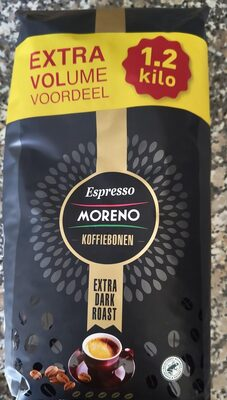

GT: EXTRA VOLUME VOORDEEL; 1.2 kilo; Espresso; MORENO; KOFFIEBONEN; EXTRA DARK ROAST
Before : EXTRA
VOLUME
VOORDEEL
1.2
kilo
Espresso
MORENO
KOFFIEBONEN
EXTRA
DARK
ROAST
FT : EXTRA VOLUME VOORDEEL 1.2 kilo; Espresso; MORENO; KOFFIEBONEN; EXTRA DARK ROAST; Espresso; MORENO; KOFFIEBONEN; EXTRA DARK ROAST; Espresso; MORENO; KOFFIEBONEN; EXTRA DARK ROAST; Espresso; MORENO; KOFFIEBONEN; EXTRA DARK ROAST; Espresso; MORENO; KOFFIEBONEN; EXTRA DARK ROAST; Espresso; MORENO; KOFFIEBONEN; EXTRA DARK ROAST; Espresso; MORENO; KOFFIEBONEN; EXTRA DARK ROAST; Espresso; MORENO; KOFFIEBONEN; EXTRA DARK ROAST; Espresso; MORENO; KOFFIEBONEN; EXTRA DARK ROAST; Espresso; MORENO; KOFFIEBONEN; EXTRA DARK ROAST; Espresso; MORENO; KOFFIEBONEN; EXTRA DARK ROAST; Espresso; MORENO; K



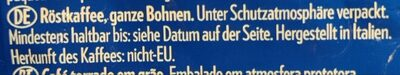

GT: DE Röstkaffee, ganze Bohnen. Unter Schutzatmosphäre verpackt. Mindestens haltbar bis: siehe Datum auf der Seite. Hergestellt in Italien. Herkunft des Kaffees: nicht-EU.
Before : DE Röstkaffee, ganze Bohnen. Unter Schutzatmosphäre verpackt.
Mindestens hatbar bis: siehe Datum auf der Seite. Hergestellt in Italien.
Herkunft des Kaffees: nicht-EU.
FT : DE Röstkaffee, ganze Bohnen. Unter Schutzatmosphäre verpackt. Mindestens hatbar bis: siehe Datum auf der Seite. Hergestellt in Italien. Herkunft des Kaffees: nicht-EU.



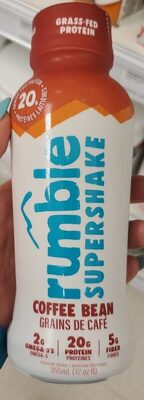

GT: 20g PROTEIN & FIBERS; GRASS-FED PROTEIN; 2g OMEGA-3; 20g PROTEIN; 5g FIBER; rumble SUPERSHAKE; COFFEE BEAN; GRAINS DE CAFÉ; 355ml (12 fl oz)
Before : GRASS-FED
PROTEIN
20
PROTEIN
CRUMBIE
SUPERSHAKE
COFFEE BEAN
GRAINS DE CAFE
2g
GRAINS 2X
GRAINS
20g
PROTEIN
PROTEINS
5g
FIBER
FIBERS
200 ml (12 oz)
FT : GRASS-FED PROTEIN; 20% PROTEIN; COFFEE BEAN; GRAINS DE CAFE; 2g GRAINS; 20g PROTEIN; 5g FIBER; 200ml; 12 oz; 40;



,sample_id,truth,Before,FT
0,HRCB:71:2003020080081_front.jpg,extra volume voordeel 1.2 kilo espresso moreno...,extra volume voordeel 1.2 kilo espresso moreno...,extra volume voordeel 1.2 kilo espresso moreno...
1,LRCB:21:8000070051003_ingredients.jpg,"de röstkaffee, ganze bohnen. unter schutzatmos...","de röstkaffee, ganze bohnen. unter schutzatmos...","de röstkaffee, ganze bohnen. unter schutzatmos..."
2,LRCB:421:0834642000247_front.jpg,20g protein & fibers grass-fed protein 2g omeg...,grass-fed protein 20 protein crumbie supershak...,grass-fed protein 20% protein coffee bean grai...
3,HRCB:420:0011225007392_ingredients.jpg,"ingredients: reverse osmosis water, 100% arabi...","ingredients: reverse osmosis water, 100% arabi...","ingredients: reverse osmosis water, 100% arabi..."
4,LRCB:532:0021130457304_front.jpg,signature select italian roast dark roast whol...,signature italian roast dark roast luhole pean...,signature coffee italian roast dark roast lush...
5,HRCB:372:50248278_front.jpg,single origin guatemalan fairtrade roast & gro...,88 thermistable single origin guatemalan fairt...,single origin guatemalan fairtrade roast & gro...
6,HRCB:411:8901058904321_front.jpg,our most intense coffee nescafé classic black ...,our most intense coffee® nescafe. classic blac...,our most intense coffee! nescafe classic black...
7,HRCB:362:0014321111420_front.jpg,allegro coffee medium roast mocha java mixed b...,allegro coffee medium roast mocha java mixed b...,allegro coffee medium roast mocha java mixed b...
8,HRCB:207:0078742434537_front.jpg,great value classic roast tostado clásico inst...,great value classic roast tostado clásico medi...,great value classic roast tostado clásico inst...
9,LRCB:559:5900788343328_front.jpg,mk café premium harmonijna kompozycja intensyw...,mk café premium harmonjna kompozycja intensywn...,premium harmonjina kompozycja intensywnośc swa...


In [ ]:
# 정답률로 선별하지 않고 고정한 앞 3개 이미지를 보여줍니다.
for i, record in enumerate(test_records[:3]):
    im = open_record(record); im.thumbnail((500, 500)); display(im)
    print('GT:', record['text'])
    for stage in ['Before', 'FT']:
        print(stage, ':', predictions[stage].iloc[i]['raw_prediction'])
    print()
merged = before_predictions[['sample_id', 'truth']].copy()
for stage, frame in predictions.items(): merged[stage] = frame['prediction']
display(merged.head(10)); merged.to_csv(OUT/'same_images_before_after.csv', index=False)


## FT 1·2·3 epoch 학습 곡선
학습 loss와 검증 loss/CER/WER를 표시합니다. 검증 loss는 전체 검증셋, 생성 지표는 고정 부분집합 기준입니다.


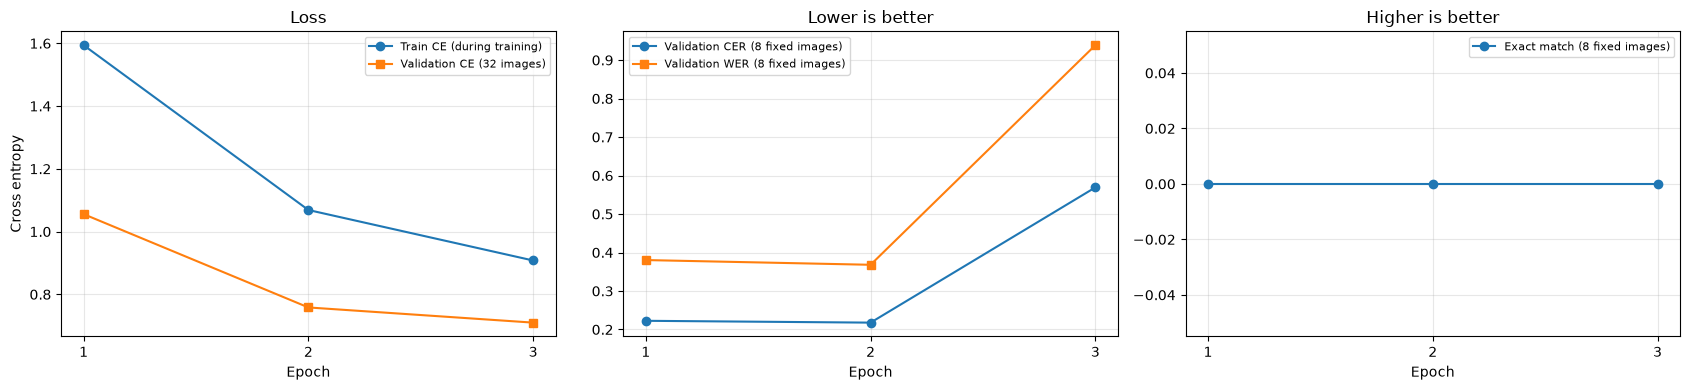

In [ ]:
hist = pd.DataFrame(history)
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
axes[0].plot(hist.global_epoch, hist.train_loss, 'o-', label='Train CE (during training)')
axes[0].plot(hist.global_epoch, hist.val_loss, 's-', label=f'Validation CE ({len(val_records)} images)')
axes[0].set_title('Loss'); axes[0].set_ylabel('Cross entropy')
axes[1].plot(hist.global_epoch, hist.val_cer, 'o-', label=f'Validation CER ({len(val_metric_ids)} fixed images)')
axes[1].plot(hist.global_epoch, hist.val_wer, 's-', label=f'Validation WER ({len(val_metric_ids)} fixed images)')
axes[1].set_title('Lower is better')
axes[2].plot(hist.global_epoch, hist.val_text_exact_match, 'o-', label=f'Exact match ({len(val_metric_ids)} fixed images)')
axes[2].set_title('Higher is better')
for ax in axes:
    ax.set_xlabel('Epoch'); ax.set_xticks(hist.global_epoch)
    ax.grid(alpha=.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT/'learning_curves.png', dpi=150); plt.show()


### 결과 해석
CER/WER는 낮을수록, 문자열 일치율은 높을수록 좋습니다. 최적 checkpoint는 전체 검증 loss 우선으로 고릅니다. 3 epoch를 모두 실행하며 최종 test는 Before와 FT 두 모델을 비교합니다.


## 12. 3 epoch를 유지하며 더 빠르게 실행하려면
- `N_TRAIN, N_VAL, N_TEST = 256, 64, 64`, `N_VAL_METRICS = 16`으로 줄이면 총 3 epoch를 유지하며 더 가볍게 실습할 수 있습니다.
- 평가 기본 batch는 2입니다. GPU 메모리가 부족하면 `EVAL_BATCH_SIZE = 1`로 바꾸고 데이터 로더 셀부터 재실행하세요.
- 충분한 GPU 메모리가 있으면 평가 batch를 4로 시도할 수 있습니다. 시간 단축 폭은 이미지 크기·글자 길이·GPU에 따라 달라집니다.
- 생성 길이와 정답 제한 256 token은 유지합니다. 긴 글자를 임의로 잘라 점수를 높이지 않습니다.
- 해상도를 줄이면 더 빨라질 수 있지만 Before부터 모든 모델을 같은 해상도로 다시 평가해야 합니다.
- 학습률·증강은 검증셋으로 조정하고 최종 test 결과를 반복 튜닝에 사용하지 않습니다.

- Jupyter에서 실행하는 것 자체가 학습을 빠르게 하지는 않습니다. 위의 `CUDA 사용 가능: True`와 실제 GPU 메모리를 확인하세요.
- Windows에서 데이터 로더는 `num_workers=0`을 유지해 프로세스 생성 관련 문제를 피합니다.


## 결과 저장
`WORK_DIR/results_ft_timed/`에 저장합니다.

- `history.csv`: loss/지표 및 train_seconds, validation_seconds, epoch_seconds, cumulative_seconds
- `timing_summary.json`: 순수 학습 총시간과 FT 루프 총시간(초)
- `comparison.csv`: Before / FT 성능 비교
- `FT/`, `selected_adapter/`, `processor/`: adapter와 processor
- `learning_curves.png`: 3 epoch 학습 곡선

시간은 이번 실행부터 측정됩니다. 에폭 합계에는 검증과 checkpoint 저장이 포함됩니다.
